# Week 4 - Jupiter Notebook 

# Forward and backward selection, principal component regression (PCR), partial least squares regression(PLSR) (Week 3)
# Logistic regression and feature scaling (Week 4) 


# Code for dataset import and EDA 
# I have done 3 data set analysis in this file Loan_Default.csv / finance-loan-approval-prediction-data / loan-approval-classification-data

In [16]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta
import os
import kagglehub

This section is for Data set 1 

In [17]:
#download teh data set 1
# Download the latest version of the dataset
path1 = kagglehub.dataset_download("yasserh/loan-default-dataset")

print("Path to dataset files:", path1)

# Construct the full path to the CSV file (update the file name if necessary)
csv_file1 = os.path.join(path1, "Loan_Default.csv")

# Read the dataset into a DataFrame
df1 = pd.read_csv(csv_file1)

# Remove duplicates if needed
df1 = df1.drop_duplicates()
#display(df1.head())
 

Path to dataset files: C:\Users\ChowdhuryT\.cache\kagglehub\datasets\yasserh\loan-default-dataset\versions\1


In [18]:
# Check duplicates across multiple columns (composite key)  # for gender , year etc duplicate value search wont be appropriate
# Exploring this for "ID" column only
columns_to_check = ['ID']  # change to your real column names

#writing generic code for multiple column for expandibility
dup_mask = df1.duplicated(subset=columns_to_check, keep=False)
dup_count = df1.duplicated(subset=columns_to_check).sum()

#print(f"Duplicate rows based on {columns_to_check}: {dup_count}")
#display(df1[dup_mask].sort_values(by=columns_to_check))
# Remove duplicates, keeping the first occurrence
df_loan_clean = df1.drop_duplicates().copy()
#print(f"\nRow count after drop_duplicates(): {len(df_loan_clean)}")

In [26]:
# Choose a missing-value strategy based on data type
 
df_loan_nullfix = df_loan_clean.copy()

#  Fill numeric columns with median
num_cols = df_loan_nullfix.select_dtypes(include=[np.number]).columns
df_loan_nullfix[num_cols] = df_loan_nullfix[num_cols].fillna(df_loan_nullfix[num_cols].median())

#  Fill non-numeric columns with mode (or 'Unknown' if mode is empty)
category_cols = df_loan_nullfix.select_dtypes(exclude=[np.number]).columns
for col in category_cols:
    mode_vals = df_loan_nullfix[col].mode(dropna=True)
    fill_val = mode_vals.iloc[0] if len(mode_vals) > 0 else 'Unknown'
    df_loan_nullfix[col] = df_loan_nullfix[col].fillna(fill_val)

print('Missing values after fill:')
print(df_loan_nullfix.isnull().sum().sum())
#print(df_loan_nullfix)
df_loan_nullfix.head(10)

Missing values after fill:
0


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,75.135870,North,direct,1,39.0
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0
5,24895,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,EXP,864,EXP,35-44,not_inst,70.089286,North,direct,0,40.0
6,24896,2019,cf,Joint,pre,type1,p3,l1,nopc,nob/c,...,EXP,860,EXP,55-64,to_inst,79.109589,North,direct,0,44.0
7,24897,2019,cf,Female,nopre,type1,p4,l1,nopc,nob/c,...,CIB,863,CIB,55-64,to_inst,86.525974,North,direct,0,42.0
8,24898,2019,cf,Joint,nopre,type1,p3,l1,nopc,nob/c,...,CIB,580,EXP,55-64,to_inst,78.765690,central,direct,0,44.0
9,24899,2019,cf,Sex Not Available,nopre,type3,p3,l1,nopc,nob/c,...,CIB,788,EXP,55-64,to_inst,63.444767,south,direct,0,30.0


In [29]:
#  Logistic regression and feature scaling on df_loan_nullfix data set 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

predictors = ['loan_amount', 'Interest_rate_spread', 'Upfront_charges', 'term',
              'property_value', 'income', 'Credit_Score', 'LTV', 'dtir1']

X = df_loan_nullfix[predictors]

# Logistic regression needs a discrete target, so use the binary 'Status'
# (loan default indicator) instead of the continuous 'rate_of_interest'.
y_clf = df_loan_nullfix['Status']

scaler = StandardScaler()
print("Scaling original")
print(X[:5])
X_scaled = scaler.fit_transform(X)
print("Scaling done")
print(X_scaled[:5])
print("Ready for modeling")

# logistic regression next
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_clf, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Model trained")

y_pred = model.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred)}")
print(classification_report(y_test, y_pred))


Scaling original
   loan_amount  Interest_rate_spread  Upfront_charges   term  property_value  \
0       116500                0.3904          2596.45  360.0        118000.0   
1       206500                0.3904          2596.45  360.0        418000.0   
2       406500                0.2000           595.00  360.0        508000.0   
3       456500                0.6810          2596.45  360.0        658000.0   
4       696500                0.3042             0.00  360.0        758000.0   

    income  Credit_Score        LTV  dtir1  
0   1740.0           758  98.728814   45.0  
1   4980.0           552  75.135870   39.0  
2   9480.0           834  80.019685   46.0  
3  11880.0           587  69.376900   42.0  
4  10440.0           602  91.886544   39.0  
Scaling done
[[-1.16697989 -0.0866192  -0.16474408  0.42560935 -1.0870095  -0.81644609
   0.50235739  0.67931655  0.73074731]
 [-0.6776066  -0.0866192  -0.16474408  0.42560935 -0.20987016 -0.30216412
  -1.27541323  0.05665677  0.109

# for doing logistic regression we need a binary targetg.   teh "status" is used a the target for teh logixtic regression . Scaling done. The model accurecy is worng .The model looks okay on accuracy (75.7%) but is actually failing at its job.

for class 1 Recall = 0.00 → it catches essentially none of the actual defaulters
Precision = 1.00 but f1 = 0.00 → it almost never predicts "default" at all
What's happening: ~76% of loans are non-default (Status=0), so a mejority class predictor model  .
Added below code for correction

              precision    recall  f1-score   support

           0       0.89      0.55      0.68     22494
           1       0.36      0.80      0.50      7240

    accuracy                           0.61     29734
   macro avg       0.63      0.67      0.59     29734
weighted avg       0.76      0.61      0.63     29734

ROC-AUC: 0.6241721610722957


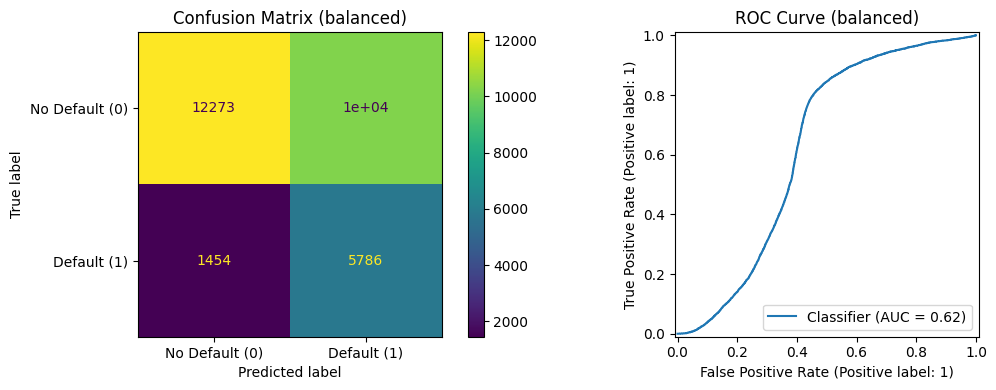

In [30]:
# Corrected logistic regression: class_weight='balanced' + ROC-AUC + confusion matrix
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay)

# Balanced weights so defaulters (minority class) are not ignored
model_bal = LogisticRegression(max_iter=1000, class_weight='balanced')
model_bal.fit(X_train, y_train)

y_pred_bal = model_bal.predict(X_test)
y_proba_bal = model_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_bal))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba_bal)}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_bal)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay(cm, display_labels=['No Default (0)', 'Default (1)']).plot(ax=ax[0])
ax[0].set_title('Confusion Matrix (balanced)')
RocCurveDisplay.from_predictions(y_test, y_proba_bal, ax=ax[1])
ax[1].set_title('ROC Curve (balanced)')
plt.tight_layout()
plt.show()


# /--------------------------------------------------------------------------------/
# This Section is for data set 2. 
# This data set has 2 Part. Train and Test data set. 
# I am going to explore both the Training and Test for its structrue/ validty/ quality .  
# I am keeping them seperate( not compining to a singe data set). 
# will run the linesr regression on teh final data set 

In [32]:
# Download the data set 2
# Download the latest version of the dataset
path2 = kagglehub.dataset_download("krishnaraj30/finance-loan-approval-prediction-data")
 
print("Path to dataset files:", path2)

# Construct the full path to the CSV file (update the file name if necessary)
csv_train_file2 = os.path.join(path2, "train.csv")
csv_test_file2 = os.path.join(path2, "test.csv")

# Read the dataset into a DataFrame
df2_train = pd.read_csv(csv_train_file2)
df2_test = pd.read_csv(csv_test_file2)
 
df2_train
df2_test
# Remove duplicates if needed
df2_train = df2_train.drop_duplicates()
 

Path to dataset files: C:\Users\ChowdhuryT\.cache\kagglehub\datasets\krishnaraj30\finance-loan-approval-prediction-data\versions\1


I am droppoing the "test" data set , as it misses the critical column "Loan_Status" 

In [33]:
# Check duplicates across multiple columns (composite key)  
# for gender , Loan ammount , tyoe  etc  duplicate value search wont be appropriate
columns_to_check = ['Loan_ID']  # change to your real column names
#writing generic code for multiple column for expandibility
dup_mask = df2_train.duplicated(subset=columns_to_check, keep=False)
dup_count = df2_train.duplicated(subset=columns_to_check).sum()

print(f" Train dataset Duplicate rows based on {columns_to_check}: {dup_count}")
#display(df2_train[dup_mask].sort_values(by=columns_to_check))
# Remove duplicates, keeping the first occurrence
df2_train_loan_clean = df2_train.drop_duplicates().copy()
print(f"Row count after drop_duplicates(): {len(df2_train_loan_clean)}")
 

 Train dataset Duplicate rows based on ['Loan_ID']: 0
Row count after drop_duplicates(): 614


In [36]:
#Choose a missing-value strategy based on data type
#Training   Dataset
df2_loan_nullfix = df2_train_loan_clean.copy()

# Parse date columns if any
date_like_cols = [c for c in df2_loan_nullfix.columns if 'date' in c.lower() or 'dt' in c.lower()]
for col in date_like_cols:
    df2_loan_nullfix[col] = pd.to_datetime(df2_loan_nullfix[col], errors='coerce')

#  Blanket fill the numeric columns with median
num_cols = df2_loan_nullfix.select_dtypes(include=[np.number]).columns
df2_loan_nullfix[num_cols] = df2_loan_nullfix[num_cols].fillna(df2_loan_nullfix[num_cols].median())

#  Blanket Fill non-numeric columns with mode (or 'Unknown' if mode is empty)
category_cols = df2_loan_nullfix.select_dtypes(exclude=[np.number]).columns
for col in category_cols:
    mode_vals = df2_loan_nullfix[col].mode(dropna=True)
    fill_val = mode_vals.iloc[0] if len(mode_vals) > 0 else 'Unknown'
    df2_loan_nullfix[col] = df2_loan_nullfix[col].fillna(fill_val)

df2_loan_nullfix.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


# Below is Regression on df2_loan_nullfix data set  ( 2 nd Data set) 

In [ ]:
# Perfomr the logistic regression and feature scaling on df2_loan_nullfix data set
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
predictors = ['Dependents','ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term',
              'Credit_History']

X = df2_loan_nullfix[predictors].copy()
# 'Dependents' has the string value '3+'; map it to numeric
X['Dependents'] = X['Dependents'].replace('3+', '3').astype(float)
y = df2_loan_nullfix['Loan_Status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.7945945945945946
              precision    recall  f1-score   support

           N       0.96      0.41      0.58        63
           Y       0.77      0.99      0.86       122

    accuracy                           0.79       185
   macro avg       0.86      0.70      0.72       185
weighted avg       0.83      0.79      0.77       185



# This data set is suitable for logictc regression to predict the Loan status. The model has bias . it missed most rejections . recall for Loan status N is 0.39 meaning it fail to catch 61% of the loan that should be rejected etc.  Adding a Class_weight ="Balanced" , random_state-42 will improve teh model performance. 
# --------------------------------------------------#

# Doing analysis on the 3rd third Data set 

In [40]:
df3 = None
try:
    
    #path3 = kagglehub.dataset_download("msfasha/loan-prediction-dataset")
    path3 = kagglehub.dataset_download("taweilo/loan-approval-classification-data")
    print("Path to dataset files:", path3)
    csv_file3 = os.path.join(path3, "loan_data.csv")
    df3 = pd.read_csv(csv_file3)
    #print(df3)
except Exception as e:
    print("Skipping df3 download (optional, not used downstream).")
    print(f"Reason: {type(e).__name__}: {e}")

Path to dataset files: C:\Users\ChowdhuryT\.cache\kagglehub\datasets\taweilo\loan-approval-classification-data\versions\1


In [41]:
# Prepare the dataset df3 by handling missing values and encoding categorical variables for regression analysis 
if df3 is not None:
    # Fill numeric columns with their median
    num_cols = df3.select_dtypes(include=[np.number]).columns
    df3[num_cols] = df3[num_cols].fillna(df3[num_cols].median())

    # Fill categorical columns with mode (or 'Unknown' if empty)
    cat_cols = df3.select_dtypes(exclude=[np.number]).columns
    for col in cat_cols:
        mode_vals = df3[col].mode(dropna=True)
        fill_val = mode_vals.iloc[0] if len(mode_vals) > 0 else 'Unknown'
        df3[col] = df3[col].fillna(fill_val)

    # Encode categorical variables into numeric dummies
    df3 = pd.get_dummies(df3, drop_first=True)

    print("df3 prepared. Shape:", df3.shape)
    print("Remaining missing values:", df3.isnull().sum().sum())
    display(df3.head())

df3 prepared. Shape: (45000, 23)
Remaining missing values: 0


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status,person_gender_male,...,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
0,22.0,71948.0,0,35000.0,16.02,0.49,3.0,561,1,False,...,True,False,False,True,False,False,False,True,False,False
1,21.0,12282.0,0,1000.0,11.14,0.08,2.0,504,0,False,...,False,False,True,False,True,False,False,False,False,True
2,25.0,12438.0,3,5500.0,12.87,0.44,3.0,635,1,False,...,False,False,False,False,False,False,True,False,False,False
3,23.0,79753.0,0,35000.0,15.23,0.44,2.0,675,1,False,...,False,False,False,True,False,False,True,False,False,False
4,24.0,66135.0,1,35000.0,14.27,0.53,4.0,586,1,True,...,True,False,False,True,False,False,True,False,False,False


In [45]:
# lets go logictic regression analysis and feature scaling with the prepared dataset df3 (after handling missing values and encoding categorical variables)

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

X = df3.drop(columns=['loan_status'])
y = df3['loan_status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.8930370370370371
              precision    recall  f1-score   support

           0       0.93      0.94      0.93     10487
           1       0.77      0.74      0.76      3013

    accuracy                           0.89     13500
   macro avg       0.85      0.84      0.84     13500
weighted avg       0.89      0.89      0.89     13500



# The logictic regression analysis has sgood resut on this data set.  This dataset has more rows (13,500 test samples) and richer/one-hot-encoded features that separate the classes well, so even plain logistic regression generalizes nicely. Accuracy 89%.

# All this loan default data is good for logoctic regression analsyis 